# BUSA3022 — Part 1: Pipeline Architecture & Evidence Diagrams

**Purpose:** Reproducible illustrations for the Data Pipeline Implementation Plan at *Really Big Bank*.

This notebook generates two high-resolution PNG images for the written report, GitHub portfolio, and presentation:

1. **Proposed architecture:** Yahoo Finance ASX 200 and FRED VIX ingestion → separate raw storage → validation, quarantine and logging → curated data → Parts 2 and 3.
2. **Proof-of-concept evidence:** observed data-quality counts and a **simulated** API-timeout retry sequence.

The counts below come from the team's terminal output on **10 October 2026**, not from a live API call. The notebook **does not fetch or modify** market data. Only diagrams are generated.

### How to run in VS Code

- Put this notebook in the project's `pipeline/` folder (or open it directly).
- Use the existing project `.venv` kernel. Install visualization dependencies in your VS Code terminal if necessary:

  ```bash
  python -m pip install matplotlib ipykernel
  ```

- Click **Run All**. The images will be saved under the project's `assets/` folder (created automatically).
- To update GitHub, add the notebook and `assets/` files to a new commit.

**Important distinctions:** The source scripts are currently launched manually; daily scheduling is **proposed, not implemented**. The ASX "raw" CSV is an uncleaned serialization of a Yahoo Finance dataframe; it is not the original HTTP payload. FRED VIX raw CSV is saved from the response bytes. Curated dates are not yet joined across Australian and US markets.

In [1]:

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Resolve path whether notebook is inside repo root or repo/pipeline.
working = Path.cwd().resolve()
if (working / "pipeline").is_dir() and (working / "data").is_dir():
    project_root = working
elif (working.parent / "pipeline").is_dir() and (working.parent / "data").is_dir():
    project_root = working.parent
else:
    project_root = working  # Standalone notebook: diagrams still render.

assets = project_root / "assets"
assets.mkdir(parents=True, exist_ok=True)
print("Illustrations will be saved in:", assets)

# Design tokens
NAVY = "#162940"
INK = "#203249"
SUBTEXT = "#50647A"
TEAL = "#E5F5F3"
TEAL_EDGE = "#13877F"
BLUE = "#EAF1FF"
BLUE_EDGE = "#3567AA"
VIOLET = "#F1ECFF"
VIOLET_EDGE = "#7260B9"
AMBER = "#FFF3DD"
AMBER_EDGE = "#C28221"
ROSE = "#FFEEEE"
ROSE_EDGE = "#BE5C65"
GREY = "#F2F5F8"
GREY_EDGE = "#B0BAC6"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})


Illustrations will be saved in: /Users/jennymagdangan/BUSA3022-Analytics/assets


## Figure 1 — proposed architecture

**Solid arrows** represent data flow. 
**Planned** areas are labelled explicitly.

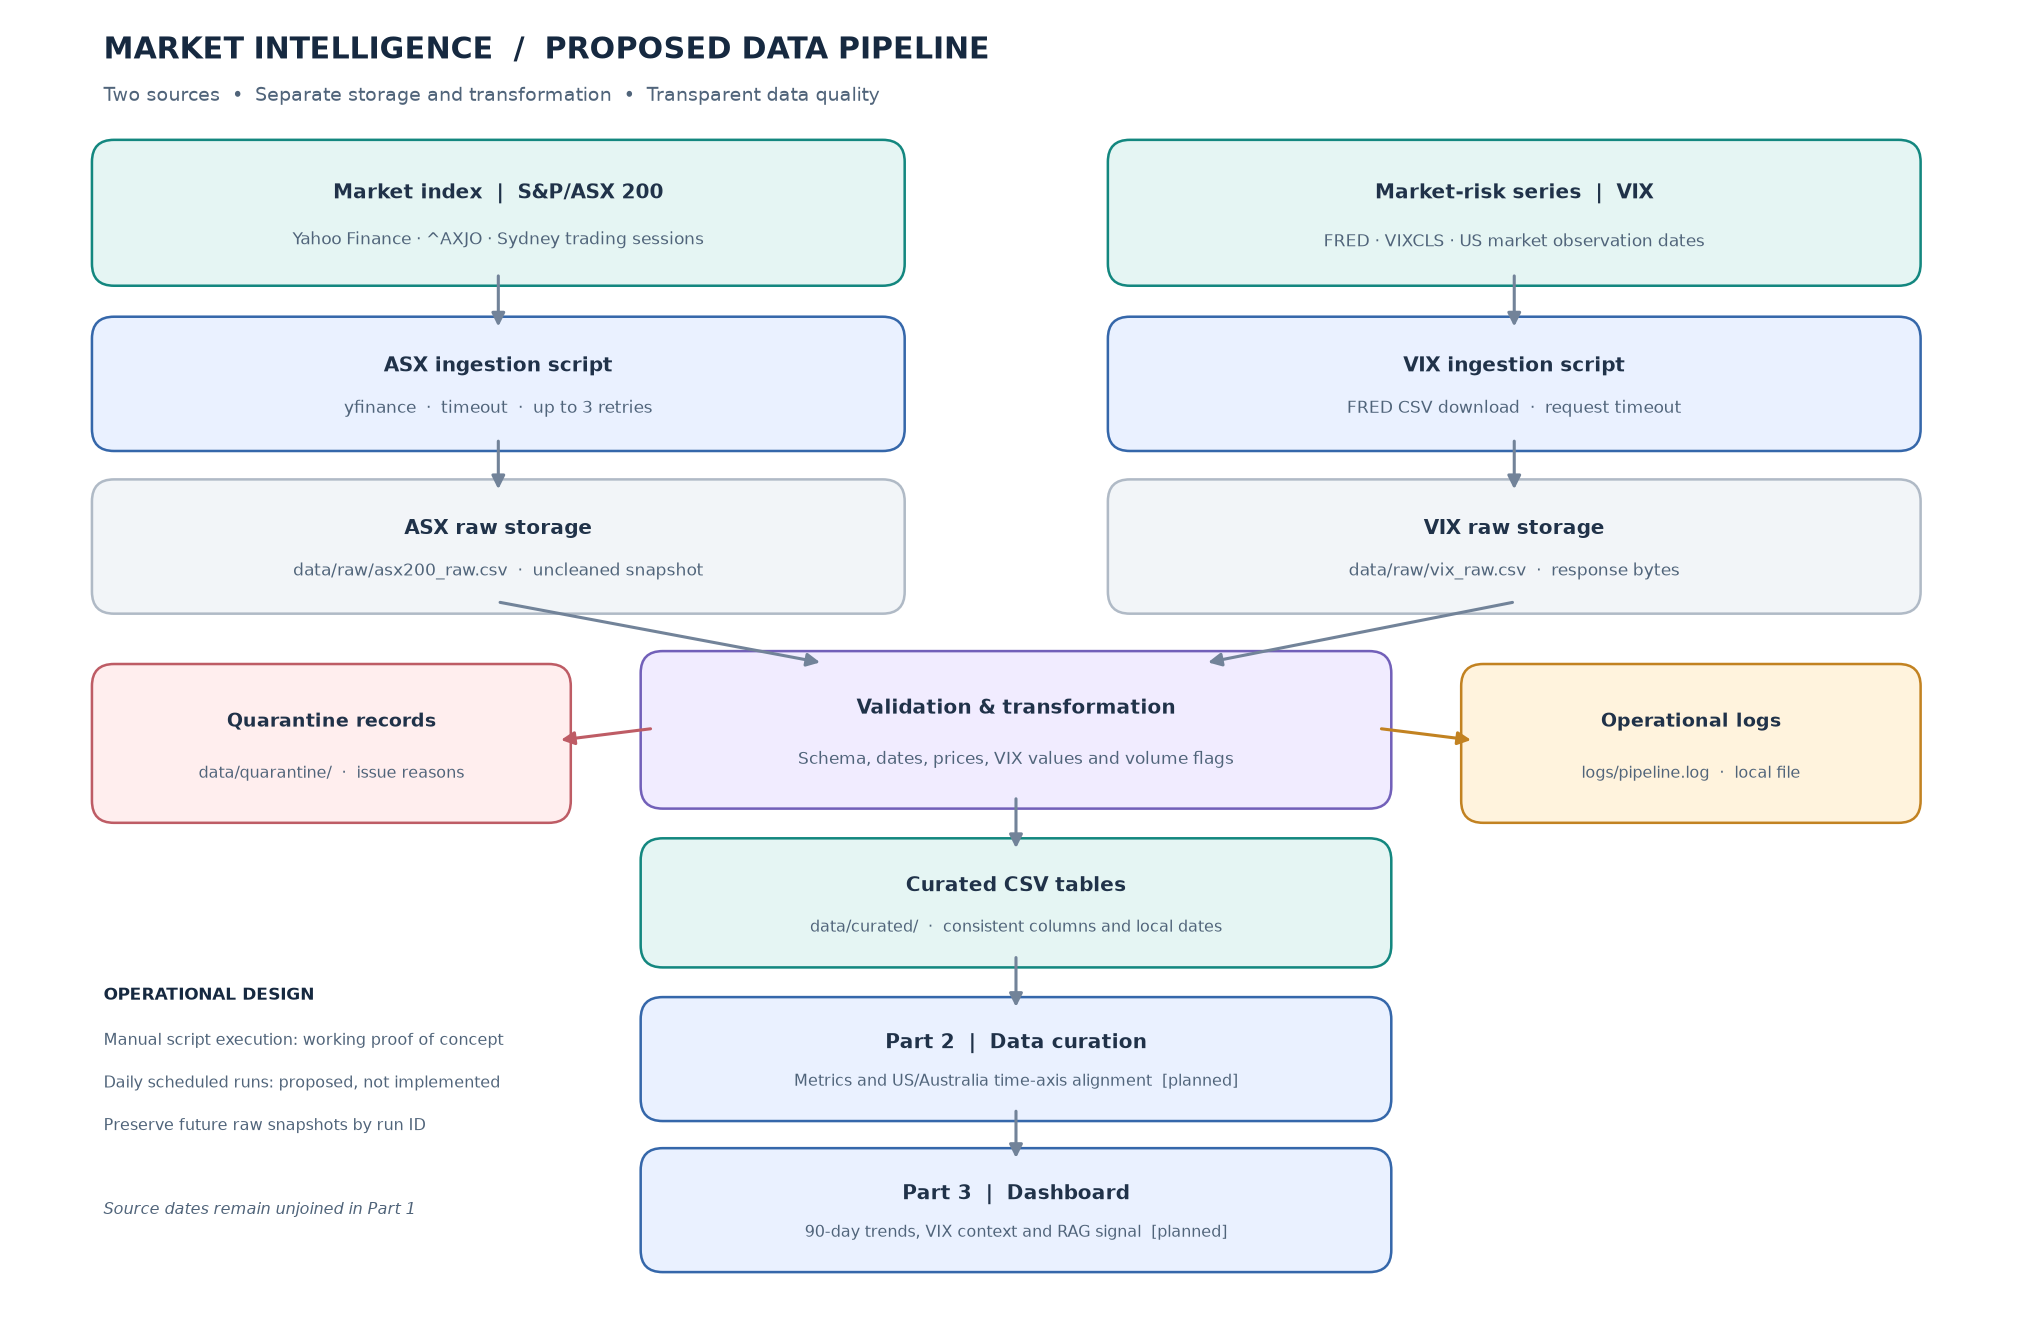

Saved: /Users/jennymagdangan/BUSA3022-Analytics/assets/part1_pipeline_architecture.png


In [ ]:

# Diagram 1 — architecture (both real and planned layers are labelled)
fig, ax = plt.subplots(figsize=(15.5, 10.1), dpi=130)
fig.patch.set_facecolor("white")
ax.set_xlim(0, 15.5)
ax.set_ylim(0, 10.1)
ax.axis("off")


def node(x, y, w, h, title, detail, face, edge, *, title_size=11.2, detail_size=9.2):
    patch = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.09,rounding_size=0.17",
                           linewidth=1.4, facecolor=face, edgecolor=edge)
    ax.add_patch(patch)
    ax.text(x+w/2, y+h*0.66, title, ha="center", va="center",
            fontsize=title_size, color=INK, fontweight="bold")
    ax.text(x+w/2, y+h*0.28, detail, ha="center", va="center",
            fontsize=detail_size, color=SUBTEXT, linespacing=1.35)
    return (x,y,w,h)


def arrow(start, end, color="#728399", lw=1.7, dashed=False):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=15,
                                 linewidth=lw, linestyle="--" if dashed else "-",
                                 connectionstyle="arc3,rad=0", color=color,
                                 shrinkA=1, shrinkB=1))

# Header
ax.text(0.70, 9.80, "MARKET INTELLIGENCE  /  PROPOSED DATA PIPELINE", fontsize=16.4,
        color=NAVY, fontweight="bold", va="center")
ax.text(0.70, 9.45, "Two sources  •  Separate storage and transformation  •  Transparent data quality",
        fontsize=10.4, color=SUBTEXT, va="center")

# Source lanes
left_x, right_x, lane_w = 0.70, 8.55, 6.10
node(left_x, 8.07, lane_w, .95, "Market index  |  S&P/ASX 200", "Yahoo Finance · ^AXJO · Sydney trading sessions", TEAL, TEAL_EDGE)
node(right_x, 8.07, lane_w, .95, "Market-risk series  |  VIX", "FRED · VIXCLS · US market observation dates", TEAL, TEAL_EDGE)
node(left_x, 6.79, lane_w, .86, "ASX ingestion script", "yfinance  ·  timeout  ·  up to 3 retries", BLUE, BLUE_EDGE)
node(right_x, 6.79, lane_w, .86, "VIX ingestion script", "FRED CSV download  ·  request timeout", BLUE, BLUE_EDGE)
node(left_x, 5.53, lane_w, .86, "ASX raw storage", "data/raw/asx200_raw.csv  ·  uncleaned snapshot", GREY, GREY_EDGE)
node(right_x, 5.53, lane_w, .86, "VIX raw storage", "data/raw/vix_raw.csv  ·  response bytes", GREY, GREY_EDGE)
for x in (left_x + lane_w/2, right_x + lane_w/2):
    arrow((x, 8.07), (x, 7.65))
    arrow((x, 6.79), (x, 6.39))

# Shared validation path
node(4.94, 4.02, 5.62, 1.04, "Validation & transformation", "Schema, dates, prices, VIX values and volume flags", VIOLET, VIOLET_EDGE)
arrow((left_x+lane_w/2, 5.53), (6.25, 5.06))
arrow((right_x+lane_w/2, 5.53), (9.22, 5.06))

# Exception and audit branches
node(0.70, 3.91, 3.52, 1.05, "Quarantine records", "data/quarantine/  ·  issue reasons", ROSE, ROSE_EDGE, title_size=10.4, detail_size=8.7)
node(11.28, 3.91, 3.37, 1.05, "Operational logs", "logs/pipeline.log  ·  local file", AMBER, AMBER_EDGE, title_size=10.4, detail_size=8.8)
arrow((4.94, 4.55), (4.22, 4.46), color=ROSE_EDGE)
arrow((10.56, 4.55), (11.28, 4.46), color=AMBER_EDGE)

node(4.94, 2.79, 5.62, .82, "Curated CSV tables", "data/curated/  ·  consistent columns and local dates", TEAL, TEAL_EDGE, detail_size=9.0)
arrow((7.75, 4.02), (7.75, 3.61))
node(4.94, 1.60, 5.62, .78, "Part 2  |  Data curation", "Metrics and US/Australia time-axis alignment  [planned]", BLUE, BLUE_EDGE, detail_size=8.8)
arrow((7.75, 2.79), (7.75, 2.38))
node(4.94, .43, 5.62, .78, "Part 3  |  Dashboard", "90-day trends, VIX context and RAG signal  [planned]", BLUE, BLUE_EDGE, detail_size=8.8)
arrow((7.75, 1.60), (7.75, 1.21))

# Operational note
ax.text(.70, 2.45, "OPERATIONAL DESIGN", color=NAVY, fontsize=9.7, weight="bold")
ax.text(.70, 2.10, "Manual script execution: working proof of concept", color=SUBTEXT, fontsize=9.0)
ax.text(.70, 1.77, "Daily scheduled runs: proposed, not implemented", color=SUBTEXT, fontsize=9.0)
ax.text(.70, 1.44, "Preserve future raw snapshots by run ID", color=SUBTEXT, fontsize=9.0)
ax.text(.70, .79, "Source dates remain unjoined in Part 1", color=SUBTEXT, fontsize=8.8, style="italic")

plt.tight_layout(pad=.25)
file_arch = assets / "part1_pipeline_architecture.png"
fig.savefig(file_arch, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", file_arch)


## Proof-of-concept evidence 

The following diagram summarises the **observed console output**, not results newly calculated from the market CSVs:

| Check | ASX 200 | FRED VIX |
|---|---:|---:|
| Raw rows | 131 | 130 |
| Rows flagged | 2 | 0 |
| Missing/invalid closing price | 0 | N/A |
| Missing/zero volume | 2 | N/A |
| Curated rows | 131 | 130 |

**Data-quality caveat:** The ASX two zero/unavailable-volume observations were quarantined for review but retained for **price-only analysis**, with their curated `volume` set to missing. Thus, flagged records are not the same as removed records.

**Retry test:** A mock raised `TimeoutError` on all four attempted calls (one original attempt plus three retries). Assertions passed for 4 attempts, 3 simulated delays and a `None` result. Because the test mock bypassed the real download, it did **not** demonstrate a live Yahoo Finance outage or verify timing against the remote service.

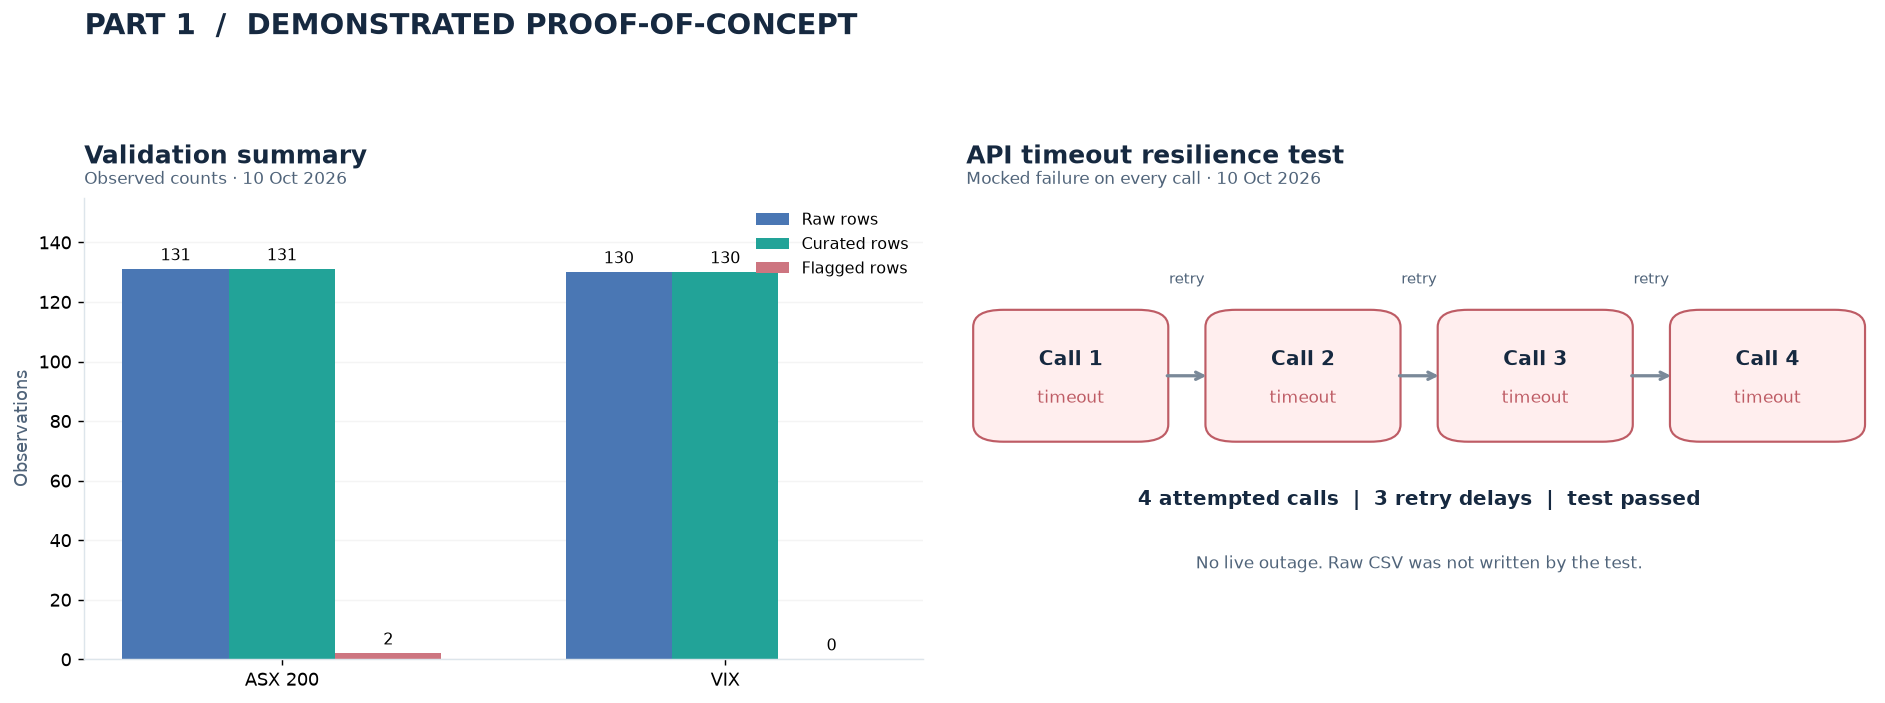

Saved: /Users/jennymagdangan/BUSA3022-Analytics/assets/part1_validation_and_retries.png


In [3]:

# Diagram 2 — historical quality checks + controlled timeout simulation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.6, 5.6), dpi=130, gridspec_kw={"width_ratios":[1,1.08]})
fig.patch.set_facecolor("white")

categories = ["ASX 200", "VIX"]
raw = [131, 130]
flagged = [2, 0]
curated = [131, 130]
xx = [0,1]
w = .24
ax1.bar([i-w for i in xx], raw, width=w, color="#4A77B4", label="Raw rows")
ax1.bar(xx, curated, width=w, color="#22A398", label="Curated rows")
ax1.bar([i+w for i in xx], flagged, width=w, color="#CD7580", label="Flagged rows")
ax1.set_xticks(xx, categories)
ax1.set_ylim(0, 155)
ax1.set_ylabel("Observations", color=SUBTEXT)
ax1.set_title("Validation summary", loc="left", fontsize=14, weight="bold", color=NAVY, pad=19)
ax1.text(0, 1.03, "Observed counts · 10 Oct 2026", transform=ax1.transAxes, color=SUBTEXT, fontsize=9.4)
ax1.spines[["top","right"]].set_visible(False)
ax1.spines[["left","bottom"]].set_color("#DDE5EB")
ax1.grid(axis="y", alpha=.13)
ax1.set_axisbelow(True)
for xpos,val in zip([i-w for i in xx],raw): ax1.text(xpos,val+3,str(val),ha="center",fontsize=9)
for xpos,val in zip(xx,curated): ax1.text(xpos,val+3,str(val),ha="center",fontsize=9)
for xpos,val in zip([i+w for i in xx],flagged): ax1.text(xpos,val+3,str(val),ha="center",fontsize=9)
ax1.legend(loc="upper right", frameon=False, fontsize=9)

# Simulated retry sequence — conceptual, not a time-series plot of elapsed waiting
ax2.set_xlim(.55,4.45)
ax2.set_ylim(0,3.5)
ax2.axis("off")
ax2.set_title("API timeout resilience test", loc="left", fontsize=14, weight="bold", color=NAVY, pad=19)
ax2.text(0, 1.03, "Mocked failure on every call · 10 Oct 2026", transform=ax2.transAxes, color=SUBTEXT, fontsize=9.4)
for i in range(1,5):
    x = i
    box = FancyBboxPatch((x-.37,1.7), .74,.9,
                         boxstyle="round,pad=0.05,rounding_size=0.13",
                         facecolor=ROSE, edgecolor=ROSE_EDGE,linewidth=1.2)
    ax2.add_patch(box)
    ax2.text(x,2.27,f"Call {i}",ha="center",va="center",fontsize=11,weight="bold",color=NAVY)
    ax2.text(x,1.98,"timeout",ha="center",va="center",fontsize=9.3,color=ROSE_EDGE)
    if i<4:
        ax2.annotate("",xy=(x+.6,2.15),xytext=(x+.4,2.15),arrowprops={"arrowstyle":"->","color":"#7A8999","lw":1.8})
        ax2.text(x+.5,2.85,"retry",ha="center",fontsize=8.4,color=SUBTEXT)
ax2.text(2.5,1.17,"4 attempted calls  |  3 retry delays  |  test passed",ha="center",fontsize=11,weight="bold",color=NAVY)
ax2.text(2.5,.69,"No live outage. Raw CSV was not written by the test.",ha="center",fontsize=9.6,color=SUBTEXT)

fig.suptitle("PART 1  /  DEMONSTRATED PROOF-OF-CONCEPT", x=.048, ha="left",
             fontsize=16.1, weight="bold", color=NAVY, y=.998)
plt.tight_layout(rect=[0,.04,1,.91], w_pad=2.4)
file_evidence = assets / "part1_validation_and_retries.png"
fig.savefig(file_evidence, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print("Saved:", file_evidence)
